In [1]:
import warnings
warnings.simplefilter('ignore', FutureWarning)

import pandas as pd

In [2]:
def roundToMillions(value): return round(value/1000000)

In [3]:
def usdToGBP(usd): return usd/1.564768

In [4]:
def expandCountry(name):
    if name == "UK":
        return "United Kingdom"
    elif name == "USA":
        return "United States"
    else:
        return name

In [5]:
# Load Data from cohort database (schema week08). See "Data Access (SQL).md".
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.dataraflow_db import run_query

GDP_INDICATOR = 'NY.GDP.MKTP.CD'
gdpReset = run_query("SELECT * FROM week08.wb_gdp_2013")

LIFE_INDICATOR = 'SP.DYN.LE00.IN'
lifeReset = run_query("SELECT * FROM week08.wb_le_2013")

In [6]:
gdpReset.head()

,country,year,NY.GDP.MKTP.CD
0,Arab World,2013,2.827557e+12
1,Caribbean small states,2013,6.928705e+10
2,Central Europe and the Baltics,2013,1.419384e+12
3,East Asia & Pacific (all income levels),2013,2.084673e+13
4,East Asia & Pacific (developing only),2013,1.172940e+13


In [7]:
lifeReset.head()

,country,year,SP.DYN.LE00.IN
0,Arab World,2013,70.631305
1,Caribbean small states,2013,71.901964
2,Central Europe and the Baltics,2013,76.127583
3,East Asia & Pacific (all income levels),2013,74.604619
4,East Asia & Pacific (developing only),2013,73.657617


In [8]:
print(gdpReset.columns.tolist())
print(lifeReset.columns.tolist())

['country', 'year', 'NY.GDP.MKTP.CD']
['country', 'year', 'SP.DYN.LE00.IN']


In [9]:
lifeReset[240:]

,country,year,SP.DYN.LE00.IN
240,Vanuatu,2013,71.669244
241,"Venezuela, RB",2013,74.074415
242,Vietnam,2013,75.756488
243,Virgin Islands (U.S.),2013,79.624390
244,West Bank and Gaza,2013,73.203341
245,"Yemen, Rep.",2013,63.583512
246,Zambia,2013,59.237366
247,Zimbabwe,2013,55.633000


In [10]:
POP_INDICATOR= "SP.POP.TOTL"
popreset=run_query(
    "SELECT * FROM week08.wb_pop_2013"
)
popreset.head()

,country,year,SP.POP.TOTL
0,Arab World,2013,3.770967e+08
1,Caribbean small states,2013,6.975819e+06
2,Central Europe and the Baltics,2013,1.037137e+08
3,East Asia & Pacific (all income levels),2013,2.248867e+09
4,East Asia & Pacific (developing only),2013,2.006073e+09


In [11]:
print(popreset.columns.tolist())

['country', 'year', 'SP.POP.TOTL']


In [12]:
popreset.head(40)

,country,year,SP.POP.TOTL
0,Arab World,2013,3.770967e+08
1,Caribbean small states,2013,6.975819e+06
2,Central Europe and the Baltics,2013,1.037137e+08
3,East Asia & Pacific (all income levels),2013,2.248867e+09
4,East Asia & Pacific (developing only),2013,2.006073e+09
5,Euro area,2013,3.372839e+08
6,Europe & Central Asia (all income levels),2013,8.988371e+08
7,Europe & Central Asia (developing only),2013,2.624163e+08
8,European Union,2013,5.065580e+08
9,Fragile and conflict affected situations,2013,4.617132e+08


In [13]:
popreset[34:]

,country,year,SP.POP.TOTL
34,Afghanistan,2013,30682500.0
35,Albania,2013,2897366.0
36,Algeria,2013,38186135.0
37,American Samoa,2013,55302.0
38,Andorra,2013,75902.0
...,...,...,...
243,Virgin Islands (U.S.),2013,104737.0
244,West Bank and Gaza,2013,4169506.0
245,"Yemen, Rep.",2013,25533217.0
246,Zambia,2013,15246086.0


In [14]:
popCountry=popreset[34:]
popData=popreset[34:]
popCountry.head()


,country,year,SP.POP.TOTL
34,Afghanistan,2013,30682500.0
35,Albania,2013,2897366.0
36,Algeria,2013,38186135.0
37,American Samoa,2013,55302.0
38,Andorra,2013,75902.0


In [15]:
popData=popCountry.dropna()
print(popData)

                   country  year  SP.POP.TOTL
34             Afghanistan  2013   30682500.0
35                 Albania  2013    2897366.0
36                 Algeria  2013   38186135.0
37          American Samoa  2013      55302.0
38                 Andorra  2013      75902.0
..                     ...   ...          ...
243  Virgin Islands (U.S.)  2013     104737.0
244     West Bank and Gaza  2013    4169506.0
245            Yemen, Rep.  2013   25533217.0
246                 Zambia  2013   15246086.0
247               Zimbabwe  2013   14898092.0

[214 rows x 3 columns]


In [16]:
popCountry=popreset.dropna()
popData=popreset.dropna()
popCountry.head()


,country,year,SP.POP.TOTL
0,Arab World,2013,3.770967e+08
1,Caribbean small states,2013,6.975819e+06
2,Central Europe and the Baltics,2013,1.037137e+08
3,East Asia & Pacific (all income levels),2013,2.248867e+09
4,East Asia & Pacific (developing only),2013,2.006073e+09


In [17]:
print("Before Cleaning:", len(popCountry))
print("After Cleaning:", len(popData))

Before Cleaning: 247
After Cleaning: 247


In [18]:
COUNTRY= "country"
POP_INDICATOR="SP.POP.TOTL"
popClean=popData[[COUNTRY,POP_INDICATOR]]
popClean.head()

,country,SP.POP.TOTL
0,Arab World,3.770967e+08
1,Caribbean small states,6.975819e+06
2,Central Europe and the Baltics,1.037137e+08
3,East Asia & Pacific (all income levels),2.248867e+09
4,East Asia & Pacific (developing only),2.006073e+09


In [19]:
gdpCountry=gdpReset[34:]
lifeCountry=lifeReset[34:]

In [20]:
gdpData=gdpCountry.dropna()
lifeData=lifeCountry.dropna()

In [21]:
COUNTRY= "country"
GDP_INDICATOR= "NY.GDP.MKTP.CD"
LIFE_INDICATORINDICATOR="SP.DYN.LEOO.IN"

gdpClean=gdpData[[COUNTRY,GDP_INDICATOR]]
lifeClean=lifeData[[COUNTRY,LIFE_INDICATOR]]



In [22]:
gdpClean.head()

,country,NY.GDP.MKTP.CD
34,Afghanistan,2.045894e+10
35,Albania,1.278103e+10
36,Algeria,2.097035e+11
38,Andorra,3.249101e+09
39,Angola,1.383568e+11


In [23]:
lifeClean.head()

,country,SP.DYN.LE00.IN
34,Afghanistan,60.028268
35,Albania,77.537244
36,Algeria,74.568951
39,Angola,51.866171
40,Antigua and Barbuda,75.778659


In [24]:
gdpVsLifeAll=pd.merge(gdpClean, lifeClean, on=COUNTRY, how="inner")
gdpVsLifeAll.head()

,country,NY.GDP.MKTP.CD,SP.DYN.LE00.IN
0,Afghanistan,2.045894e+10,60.028268
1,Albania,1.278103e+10,77.537244
2,Algeria,2.097035e+11,74.568951
3,Angola,1.383568e+11,51.866171
4,Antigua and Barbuda,1.200588e+09,75.778659


In [25]:
GDP = "GDP (£m)"

gdpVsLifeAll[GDP] = (
    gdpVsLifeAll[GDP_INDICATOR]
    .apply(usdToGBP)
    .apply(roundToMillions)
)

In [26]:
LIFE= "Life expectancy (years)"
gdpVsLifeAll[LIFE]=(gdpVsLifeAll[LIFE_INDICATOR].apply(round))

In [27]:
gdpVsLifeAll.head()

,country,NY.GDP.MKTP.CD,SP.DYN.LE00.IN,GDP (£m),Life expectancy (years)
0,Afghanistan,2.045894e+10,60.028268,13075,60
1,Albania,1.278103e+10,77.537244,8168,78
2,Algeria,2.097035e+11,74.568951,134016,75
3,Angola,1.383568e+11,51.866171,88420,52
4,Antigua and Barbuda,1.200588e+09,75.778659,767,76


In [28]:
headings=[COUNTRY, GDP, LIFE]
gdpVsLifeClean= gdpVsLifeAll[headings]
gdpVsLifeClean.head()

,country,GDP (£m),Life expectancy (years)
0,Afghanistan,13075,60
1,Albania,8168,78
2,Algeria,134016,75
3,Angola,88420,52
4,Antigua and Barbuda,767,76


In [29]:
gdpLifePopulation=pd.merge(gdpVsLifeClean, popClean, on=COUNTRY, how="inner")
gdpLifePopulation.head()

,country,GDP (£m),Life expectancy (years),SP.POP.TOTL
0,Afghanistan,13075,60,30682500.0
1,Albania,8168,78,2897366.0
2,Algeria,134016,75,38186135.0
3,Angola,88420,52,23448202.0
4,Antigua and Barbuda,767,76,89985.0


In [30]:
POPULATION= "Population (millions)"
gdpLifePopulation[POPULATION]= (gdpLifePopulation[POP_INDICATOR].apply(roundToMillions)
)
gdpLifePopulation[POPULATION].head()

0    31
1     3
2    38
3    23
4     0
Name: Population (millions), dtype: int64

In [31]:
headings=[COUNTRY,GDP,LIFE, POPULATION]
gdpLifePopulationClean=gdpLifePopulation[headings]
gdpLifePopulationClean.head()


,country,GDP (£m),Life expectancy (years),Population (millions)
0,Afghanistan,13075,60,31
1,Albania,8168,78,3
2,Algeria,134016,75,38
3,Angola,88420,52,23
4,Antigua and Barbuda,767,76,0


In [32]:
#correlation
from scipy.stats import spearmanr

In [33]:
gdpColumn = gdpVsLifeClean[GDP]
lifeColumn = gdpVsLifeClean[LIFE]

correlation, pValue = spearmanr(
    gdpColumn,
    lifeColumn
)

print("The correlation is", correlation)
print("The p-value is", pValue)

if pValue < 0.05:
    print("It is statistically significant.")
else:
    print("It is not statistically significant.")

The correlation is 0.5010232389671027
The p-value is 3.261405703360045e-13
It is statistically significant.


In [34]:
gdpColumn = gdpVsLifeClean[GDP]
populationColumn = gdpLifePopulationClean[POPULATION]

correlation, pValue = spearmanr(
    gdpColumn,
    populationColumn
)

print("The correlation is", correlation)
print("The p-value is", pValue)

if pValue < 0.05:
    print("It is statistically significant.")
else:
    print("It is not statistically significant.")

The correlation is 0.7056367228611176
The p-value is 2.448452039575652e-29
It is statistically significant.


<Axes: xlabel='GDP (£m)', ylabel='Life expectancy (years)'>

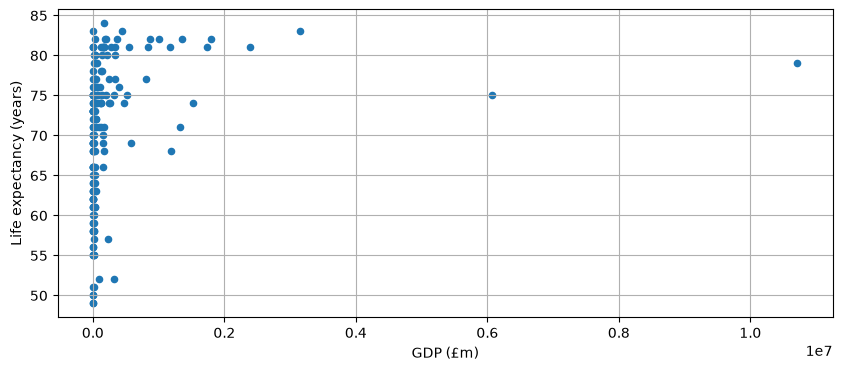

In [35]:
gdpLifePopulationClean.plot(
    x=GDP,
    y=LIFE,
    kind='scatter',
    grid=True,
    figsize=(10,4)
)

<Axes: xlabel='GDP (£m)', ylabel='Life expectancy (years)'>

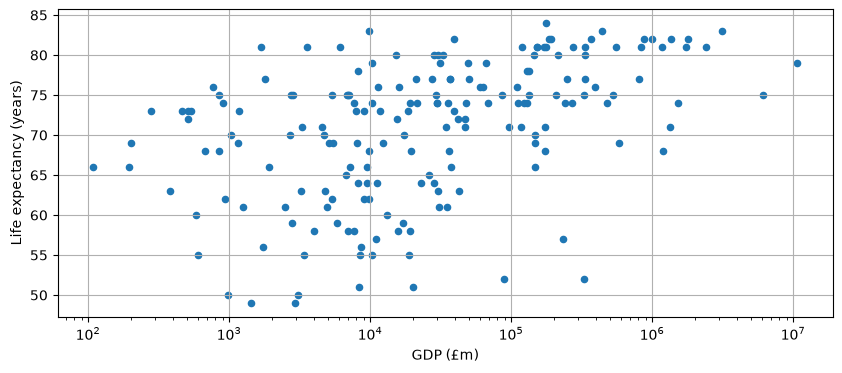

In [36]:
gdpLifePopulationClean.plot(
    x=GDP,
    y=LIFE,
    kind='scatter',
    grid=True,
    logx=True,
    figsize=(10,4)
)

<Axes: xlabel='Life expectancy (years)', ylabel='GDP (£m)'>

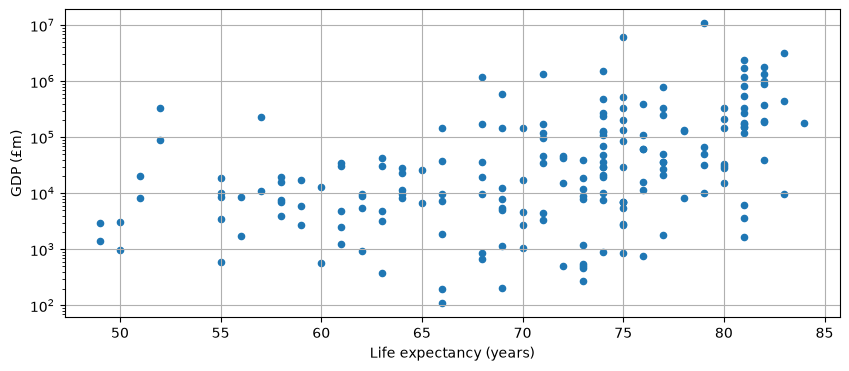

In [37]:
gdpLifePopulationClean.plot(
    x=LIFE,
    y=GDP,
    kind='scatter',
    grid=True,
    logy=True,
    figsize=(10,4)
)

<Axes: xlabel='GDP (£m)', ylabel='Population (millions)'>

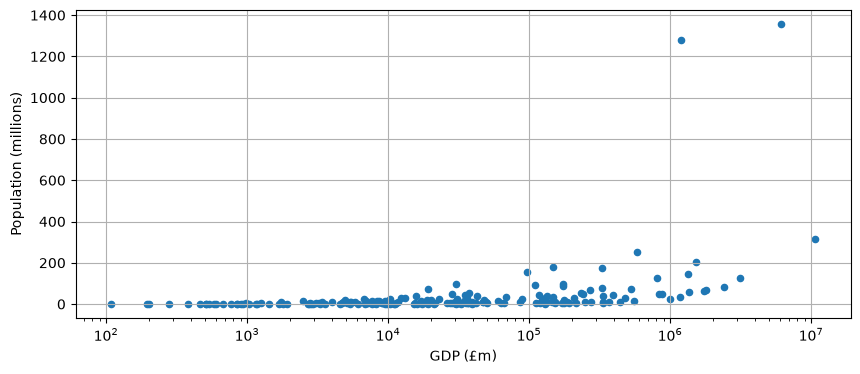

In [38]:
gdpLifePopulationClean.plot(
    x=GDP,
    y=POPULATION,
    kind='scatter',
    grid=True,
    logx=True,
    figsize=(10,4)
)

In [39]:
# ASSIGNMENT
top_10_gdp= gdpLifePopulationClean.sort_values(by=GDP, ascending=False).head(10)
top_10_gdp[[COUNTRY,GDP,LIFE]]

,country,GDP (£m),Life expectancy (years)
177,United States,10715999,79
35,China,6065182,75
83,Japan,3143957,83
62,Germany,2393529,81
58,France,1795953,82
176,United Kingdom,1733354,81
23,Brazil,1528714,74
81,Italy,1363486,82
138,Russian Federation,1328647,71
75,India,1189826,68


In [40]:
top_10_life=gdpLifePopulationClean.sort_values(by=LIFE, ascending=False).head(10)
top_10_life[[COUNTRY, LIFE, GDP]]

,country,Life expectancy (years),GDP (£m)
72,"Hong Kong SAR, China",84,176220
74,Iceland,83,9827
162,Switzerland,83,437713
83,Japan,83,3143957
80,Israel,82,186870
81,Italy,82,1363486
58,France,82,1795953
99,Luxembourg,82,39491
7,Australia,82,999478
161,Sweden,82,369858


In [41]:
gdp_countries = set(top_10_gdp[COUNTRY])
life_countries = set(top_10_life[COUNTRY])

common_countries = gdp_countries.intersection(life_countries)

print("Countries in both top-ten lists:")
print(sorted(common_countries))

print("Number of countries in both lists:", len(common_countries))

Countries in both top-ten lists:
['France', 'Italy', 'Japan']
Number of countries in both lists: 3


In [42]:
#2.
median_gdp = gdpVsLifeClean[GDP].median()

lower_life_higher_gdp = gdpVsLifeClean[
    (gdpVsLifeClean[GDP] > median_gdp) &
    (gdpVsLifeClean[LIFE] < 60)
]

lower_life_higher_gdp[[COUNTRY, GDP, LIFE]]

,country,GDP (£m),Life expectancy (years)
3,Angola,88420,52
124,Nigeria,329100,52
152,South Africa,234056,57


In [43]:
GDP_PER_CAPITA = "GDP per capita (£ per person)"

gdpLifePopulationClean[GDP_PER_CAPITA] = (
    gdpLifePopulationClean[GDP] /
    gdpLifePopulationClean[POPULATION]
)

gdpLifePopulationClean[
    [COUNTRY, GDP, POPULATION, GDP_PER_CAPITA, LIFE]
].head()

,country,GDP (£m),Population (millions),GDP per capita (£ per person),Life expectancy (years)
0,Afghanistan,13075,31,421.774194,60
1,Albania,8168,3,2722.666667,78
2,Algeria,134016,38,3526.736842,75
3,Angola,88420,23,3844.347826,52
4,Antigua and Barbuda,767,0,inf,76


In [44]:
correlation, pValue = spearmanr(
    gdpLifePopulationClean[GDP_PER_CAPITA],
    gdpLifePopulationClean[LIFE]
)

print("Spearman correlation:", correlation)
print("p-value:", pValue)

if pValue < 0.05:
    print("It is statistically significant.")
else:
    print("It is not statistically significant.")

Spearman correlation: 0.7528393122622955
p-value: 2.943403084175504e-35
It is statistically significant.


<Axes: xlabel='GDP per capita (£ per person)', ylabel='Life expectancy (years)'>

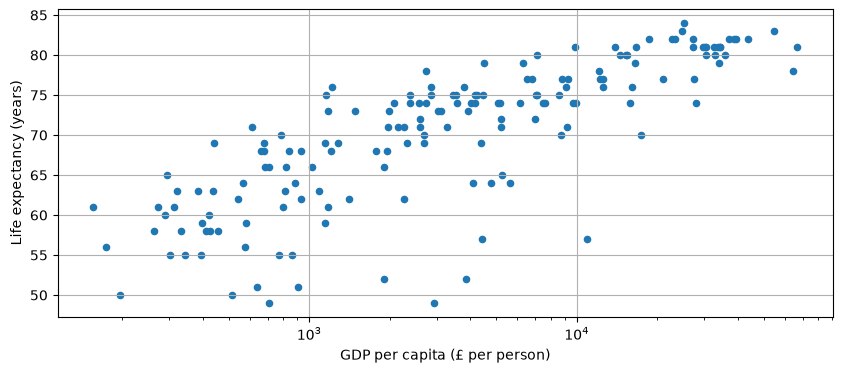

In [45]:
gdpLifePopulationClean.plot(
    x=GDP_PER_CAPITA,
    y=LIFE,
    kind="scatter",
    grid=True,
    logx=True,
    figsize=(10, 4)
)

In [46]:
gdpLifePopulationClean.to_csv("week08.wb_pop_2013.csv", index=False)
print("GDP AND LIFE DATA saved successfully")

GDP AND LIFE DATA saved successfully
